# Third pass: hypotheses, matched comparisons and negative results

The previous pass achieved a screenshot-reported public score of **0.76756**,
rank **568**. File attribution follows the conversation; the screenshot does
not show a filename. This notebook reviews a new, prospectively planned pass
using only supplied rows. The public score does not select experiments.

The main question is whether tuning **after** finding better features improves
the result. New features and other model families follow the recorded plan.
Full details and exact per-trial configurations: `ROUND3_EXPERIMENT_LOG.md`.
Existing notebooks are unchanged.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if not (ROOT/'input').exists():
    ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'input/train.csv').exists())
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve(), 'Use the project local venv'
sys.path.insert(0,str(ROOT/'improvements/round3'))
import round3 as t
import validate as v
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ART=t.ART
print('Python:',sys.executable)
print('Third-pass implementation:',t.implementation_hash())

/Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Matplotlib is building the font cache; this may take a moment.


Python: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python
Third-pass implementation: a1e121c4ca79cef4ac80c526a939528f09a2c74e0d63d9262dbe29e2aa81f01f


In [2]:
display(Markdown((t.HERE/'PLAN.md').read_text()))
display(Markdown((t.HERE/'FOLLOWUP_PLAN.md').read_text()))
display(Markdown((t.HERE/'BAGGING_PLAN.md').read_text()))
display(pd.Series(t.read(ART/'public_feedback.json')))

# Third-pass plan, recorded before fitting

The current reference is the complete round-two recipe, not the weaker first-pass
model. The user reports public AUC 0.76756, rank 568. Attribution to
`submission_round2.csv` follows the conversation; the screenshot itself does not
identify a file. Public feedback will not select parameters or ensemble weights.

## Questions and priority

1. Does tuning the successful 51-column loan-proxy representation improve it?
   Test depth, learning rate, shrinkage, split policy, numeric resolution, class
   weighting, missing policy and training-fold group aggregates. Earlier tuning
   mostly preceded this representation.
2. Can a few explicit changes to that representation improve it? Isolate signed
   term distances/coarse categories, additional hypothetical rate transforms,
   categorical interactions, and the larger original feature set. These are
   redundant representations of supplied values, not recovered financial facts.
3. Does a different learner add complementary errors? Test the same compact
   representation in LightGBM, XGBoost and a small neural network trained from
   scratch. Preprocessing and all aggregates fit only the training fold.
4. Can probability, log-odds or training-reference percentile blending improve
   the current recipe? Test using stored OOF predictions before considering any
   learned stacker. A stacking experiment must hold out meta-fitting rows and
   acknowledge that ordinary precomputed OOF features are not fully nested.

## Evaluation rules

- Reuse the original inner split only for inexpensive screening. It is heavily
  explored, so its result is not independent evidence.
- Initially screen the explicit configurations in `candidate_plan.json`.
  Record hypotheses, exact settings, runtime, convergence and all failures.
- Promote at most four new models: up to two best CatBoost screens, the best
  other tree model, and the neural network, only when a coarse blend with the
  complete current reference improves inner AUC by at least 0.00010. Promotions
  may include a weaker individual model if it provides ensemble improvement.
- Compare promoted models with the frozen round-two recipe on its original
  five development folds. Explore a small, recorded blend grid only here.
  Compare methods with the same base model bank; do not confuse seed averaging
  with a feature improvement. Require primary OOF gain >= 0.00020.
- Freeze one winning recipe, weights, iteration counts, inference transform and
  implementation hashes before confirmation. Use a new fold seed with fixed
  iteration counts for candidate and reference. Do not tune on this result.
  Require positive pooled gain and positive gains in at least four of five
  confirmation folds. This changes the partition, not the available labels;
  it is a robustness check, not an untouched test.
- For two-seed final bagging, obtain matching secondary-development OOF for each
  accepted new family. Require averaged-candidate AUC to exceed the complete
  current two-seed recipe by >= 0.00020. Do not drop the current bank's second
  seed merely to make an easier comparison. A failed gate retains round two.
- Fit any accepted final recipe at training lengths frozen from development.
  Full-data OOF remains diagnostic and will not retune selection.

## Follow-ups and stopping

Follow up clear component or parameter improvements with matched controls and
write an amendment before any additional fit. If a phase produces no repeatable
gain, move to the next distinct hypothesis. Record the remaining untested ideas,
practical costs and uncertainty. Do not claim a global optimum or that every
possible method has been exhausted.

Existing notebooks and previous-pass source/model artifacts are immutable.
Only new notebooks will be created, using the project `.venv`. No online data,
pretrained weights, recovered test labels or pseudo-labels will be introduced.

## Deliverables

New executed notebook(s), complete third-pass experiment journal and machine
ledger, updated main report, verified reproduction archive, and either a
locally justified new CSV or an explicit recommendation to retain round two.

## Primary pair-grid correction

A primary-only implementation review identified missing direct new/new and old/new family pairs. The exact fixed coarse grid and reason are recorded in `artifacts/pair_grid_amendment.json`. The first confirmation was interrupted without consulting its results, and its evidence and original source/freeze were preserved under `reference/selection_before_pair_extension`. A fresh confirmation seed, SEED+1101, evaluates the amended primary winner. No confirmation score selects its weights.


# Quantization follow-up, recorded during the initial screen

Observed trigger: `r3_cat_borders512` inner AUC 0.7508330687 versus the
matched proxy CatBoost 0.7499521163 (+0.0008809524). Its best coarse blend
with the complete current recipe scored 0.7514878320, about +0.000257.
The old lean-feature 512-border trial had been negative. This supports testing
parameter/representation interaction rather than assuming the old result transfers.

After the initial twenty screens finish, test:

1. 1024 borders, otherwise identical to the proxy baseline: is there a useful
   quantization trend, or did the single finer grid happen to fit this split?
2. Depth four plus 512 borders: does the separately promising shallower tree
   complement the finer representation?
3. Native missing bins plus 512 borders: does this complement quantization or
   change the useful numeric thresholds adversely?
4. If a new feature block (`signed`, `rates`, `crosses`, `engineered_proxy`)
   beats the matched baseline individually and gains >=0.00010 in a blend,
   combine the highest blend-scoring such block with 512 borders. Otherwise,
   do not invent a feature-combination experiment after seeing it fail.
5. Increase resolution only for the original credit/annuity ratio and five new
   loan-proxy columns, keeping all other columns at the default. This separates
   the hypothesized loan-threshold mechanism from a global border-count change.
6. Increase resolution only for the original/aggregate external-score columns.
   This is a matched alternative explanation for the global quantization gain.

Items 5–6 were added before any follow-up fit, after checking the installed
CatBoost parameter documentation for per-column quantization. Column indexes
are generated from the actual encoded schema, not guessed or learned from test
data. These controls can weaken a proposed explanation even if the global
512-border recipe remains useful.

The subsequently completed `r3_cat_signed` screen scored 0.7509073195,
with best-blend AUC 0.7516576204 (about +0.000426 over the full reference).
Before any follow-up fit, add two component controls using CatBoost's explicit
ignored-feature mechanism on the exact same 55-column frame:

7. Keep only the two signed residual additions; ignore rounded categories.
8. Keep only the two rounded category additions; ignore signed residuals.

This tests which part of the joint term representation is useful. Neither the
feature-function implementation nor the previous screening caches are changed.

Exact generated specs are frozen in `artifacts/followup_plan.json` before
any of these follow-up fits. Include all completed follow-ups in the same
promotion ranking and retain the original finalist limits and validation gates.
Do not use confirmation feedback to add another search cycle.


# Three-seed averaging check, recorded before confirmation

The previous pass benefited from averaging two fold seeds. The third-pass
confirmation already produces a third development OOF prediction for every
family in the frozen recipe and the complete current reference. Those saved
predictions permit a low-cost, prospective test of diminishing averaging gains.

Only run this check if the original third-pass primary, confirmation and
two-seed gates all pass. Keep its recipe, weights and prediction transform fixed.
Average matching family predictions over the original primary seed, previous
secondary seed and new confirmation seed, before applying the frozen transform.

Train a third final seed only if ALL of these predeclared conditions hold:

- The current reference gains at least 0.00020 AUC from two to three seeds.
- The candidate gains at least 0.00020 AUC from two to three seeds.
- The three-seed candidate still beats the three-seed current reference by at
  least 0.00020, so a feature gain is not confused with additional averaging.
- Both candidate and reference improve in at least four of five primary-fold
  row groups. These groups summarize the gains; they are not independent tests.

If the gate fails, retain the original two-seed decision and stop expanding the
seed bank. No search over seed subsets, unequal seed weights or four-seed run.
This is a conditional development diagnostic, not new independent evidence.

If it passes, freeze the probe/source/recipe before any additional full-data fit.
Use final fold seed SEED+602, model seeds SEED+900+k, and the same frozen median
iteration counts. Reuse all original two-seed model instances. Preserve the
two-seed CSV and create a separately named three-seed CSV. Verify saved-model
replay and report the incremental gain separately.


score                                                           0.76756
rank                                                                568
previous_score                                                   0.7654
score_gain                                                      0.00216
source                User-provided leaderboard screenshot, hasanRoc...
submission                                 output/submission_round2.csv
sha256                ca654e22e1f0e4d807456e666d6fd9562d31979dc0f6ed...
file_attribution      Inferred from conversation sequence; screensho...
used_for_selection                                                False
dtype: object

## Feature definitions and constraints

The reference representation contains the previous compact predictors plus
three hypothetical rate transforms and two term-distance transforms. New
blocks isolate signed term residuals/coarse categories, extra assumed periods,
explicit categorical crosses, or the larger original representation.

None recovers a real loan schedule or interest rate. Rates solve the assumed
annuity equation for a declared period count. Signed distances retain the
direction relative to a rounded multiple. All are functions of supplied row
values. Group aggregates, neural quantiles and category vocabularies fit only
training rows. IDs and targets are excluded.

In [3]:
train,test,y,split=t.load()
counts=[dict(representation=m,columns=t.features(train.iloc[:10],m).shape[1])
        for m in ['proxy','signed','rates','crosses','engineered_proxy']]
display(pd.DataFrame(counts))
print('Training rows:',len(train),'test rows:',len(test),'positive rate:',y.mean())
display(pd.Series(t.read(ART/'preflight.json')))

,representation,columns
0,proxy,51
1,signed,55
2,rates,56
3,crosses,55
4,engineered_proxy,81


Training rows: 171202 test rows: 61500 positive rate: 0.08072919708881905


protected_hashes_match                                                    True
venv                                                                      True
features_ignore_ID_TARGET                                                 True
row_batch_invariance                                                      True
train_test_schema_matches                                                 True
implementation_hash          a1e121c4ca79cef4ac80c526a939528f09a2c74e0d63d9...
dtype: object

## Every screen, including failures

Scores below use the repeatedly explored inner split. The baseline is the
**complete current mixture**, not only its lead CatBoost component. A weaker
individual model can still be useful when its errors differ. Screening
complementarity must survive five-fold validation and frozen confirmation.

In [4]:
rows=t.screen_rows()
complete=[a for a in rows if a['status']=='complete']
frame=pd.DataFrame([dict(name=a['name'],kind=a['spec']['kind'],auc=a.get('auc'),
    blend_auc=a.get('best_blend',{}).get('auc'),
    blend_gain=a.get('best_blend',{}).get('auc',np.nan)-a.get('reference_auc',np.nan),
    iterations=a.get('iterations'),seconds=a.get('seconds'),status=a['status']) for a in rows])
display(frame.sort_values('blend_auc',ascending=False))
control=next(a for a in complete if a['name']=='r3_cat_baseline')
assert control['baseline_max_difference']==0
print('Control maximum prediction difference:',control['baseline_max_difference'])

,name,kind,auc,blend_auc,blend_gain,iterations,seconds,status
23,r3_lgb_proxy,lgb,0.748054,0.751715,0.000484,757,17.428949,complete
10,r3_cat_feature_b512,cat,0.750854,0.751707,0.000476,1851,192.839830,complete
24,r3_lgb_proxy_smooth,lgb,0.748929,0.751686,0.000455,876,17.398490,complete
18,r3_cat_signed,cat,0.750907,0.751658,0.000426,1528,195.142987,complete
1,r3_cat_borders1024,cat,0.750539,0.751548,0.000316,2072,194.777572,complete
9,r3_cat_engineered_proxy,cat,0.750087,0.751546,0.000315,1802,230.971784,complete
5,r3_cat_depth4_b512,cat,0.750716,0.751528,0.000297,2176,168.933482,complete
15,r3_cat_native_b512,cat,0.750487,0.751489,0.000257,1973,202.011320,complete
2,r3_cat_borders512,cat,0.750833,0.751488,0.000257,1621,181.536811,complete
19,r3_cat_signed_only,cat,0.750268,0.751463,0.000232,1810,175.709334,complete


Control maximum prediction difference: 0.0


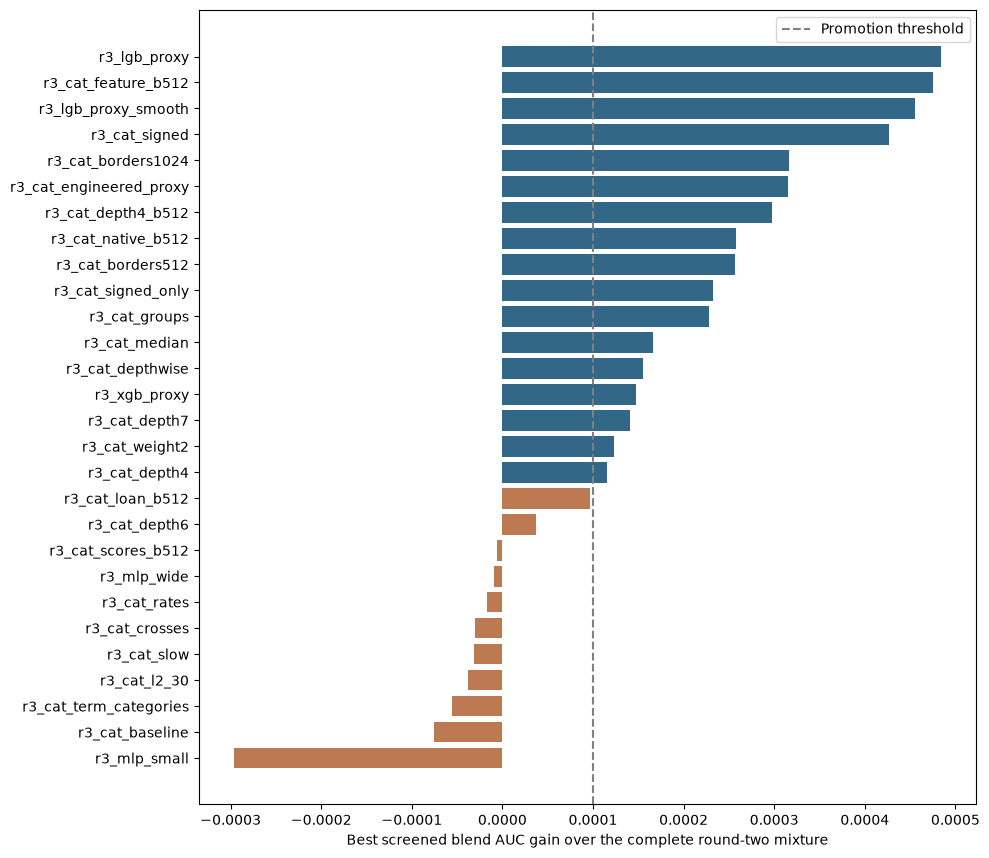

In [5]:
plot=frame[frame.status=='complete'].sort_values('blend_gain')
fig,ax=plt.subplots(figsize=(10,max(5,len(plot)*.31)))
ax.barh(plot.name,plot.blend_gain,color=np.where(plot.blend_gain>=.0001,'#326788','#bd7952'))
ax.axvline(.0001,color='gray',linestyle='--',label='Promotion threshold')
ax.set_xlabel('Best screened blend AUC gain over the complete round-two mixture')
ax.legend();fig.tight_layout();plt.show()

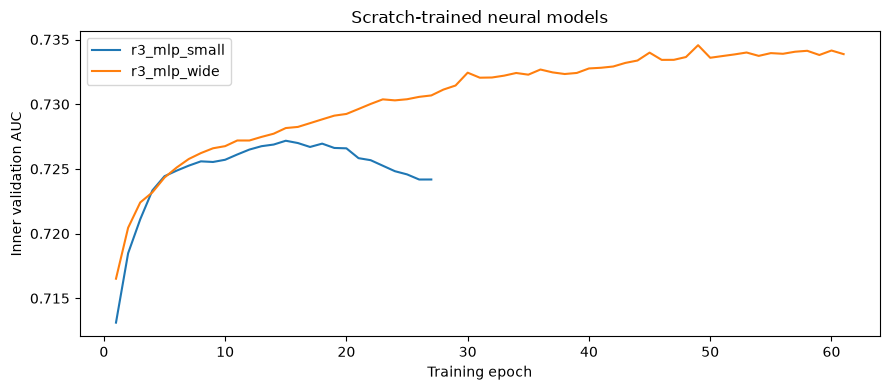

In [6]:
neural=[a for a in complete if a['spec']['kind']=='mlp']
if neural:
    fig,ax=plt.subplots(figsize=(9,4))
    for a in neural:
        curve=t.read(ART/'screen'/(a['name']+'_curve.json'))
        ax.plot([b['epoch'] for b in curve],[b['validation_auc'] for b in curve],label=a['name'])
    ax.set(xlabel='Training epoch',ylabel='Inner validation AUC',title='Scratch-trained neural models')
    ax.legend();fig.tight_layout();plt.show()

## Current-model slices and blend-only diagnostics

Slice differences are exploratory. Sparse categories have unstable estimates;
a lower slice AUC alone does not justify a specialist model. The percentile
transform is a ranking score rather than a calibrated default probability.

In [7]:
display(pd.read_csv(ART/'current_model_slice_diagnostic.csv'))
display(pd.DataFrame(t.read(ART/'early_blend_diagnostic.json')))
if (ART/'stacking_probe.json').exists():
    probe=t.read(ART/'stacking_probe.json')
    display(pd.DataFrame([dict(name=a['spec']['name'],auc=a['auc'],best_blend_gain=a['gain']) for a in probe['results']]))
    print(probe['caveat'])
    print('Warrants fully nested follow-up:',probe['warrants_nested_followup'])
display(pd.Series(t.read(ART/'promotion.json')))

,slice,group,count,positives,observed_rate,mean_prediction,mean_residual,auc,log_loss
0,EXT_MISSING_COUNT,0,28971,2050,0.070760,0.069738,0.001023,0.775537,0.220921
1,EXT_MISSING_COUNT,1,77134,6210,0.080509,0.079678,0.000831,0.767463,0.243010
2,EXT_MISSING_COUNT,2,30767,2791,0.090714,0.090563,0.000151,0.742234,0.269840
3,EXT_MISSING_COUNT,3,89,6,0.067416,0.090088,-0.022673,0.680723,0.234781
4,NAME_CONTRACT_TYPE,Cash loans,124000,10337,0.083363,0.082378,0.000985,0.763264,0.249840
5,NAME_CONTRACT_TYPE,Revolving loans,12961,720,0.055551,0.057537,-0.001985,0.757210,0.191924
6,NAME_INCOME_TYPE,Businessman,2,0,0.000000,0.012884,-0.012884,NaN,0.012968
7,NAME_INCOME_TYPE,Commercial associate,32083,2403,0.074899,0.074649,0.000251,0.753490,0.235325
8,NAME_INCOME_TYPE,Maternity leave,3,1,0.333333,0.022111,0.311223,1.000000,1.057077
9,NAME_INCOME_TYPE,Pensioner,24542,1321,0.053826,0.052441,0.001385,0.733510,0.189726


,method,primary_auc,previous_secondary_auc,note
0,probability,0.763089,0.762876,Diagnostic only; previous secondary labels hav...
1,log_odds,0.763044,0.762852,Diagnostic only; previous secondary labels hav...
2,percentile,0.763026,0.762856,Diagnostic only; previous secondary labels hav...


,name,auc,best_blend_gain
0,logits_c01,0.762943,0.000002
1,logits_c1,0.762943,0.000002
2,logits_groups_c01,0.762849,-0.000004


Meta folds hold out their own meta targets, but precomputed base OOF features are not fully nested. Screening evidence only; never deploy from this probe.
Warrants fully nested follow-up: False


rule         At most 2 CatBoost, 1 other tree, 1 neural mod...
chosen       [{'name': 'r3_cat_feature_b512', 'spec': {'nam...
decisions    [{'name': 'r3_cat_borders1024', 'promoted': Fa...
dtype: object

## Exact trial record and interpretation

Interpretations distinguish observed effects from proposed mechanisms. A
negative result does not establish universal ineffectiveness. Operational
incidents and corrections are retained in the journal.

In [8]:
ledger=t.read(ART/'experiment_ledger.json')
for a in ledger:
    display(Markdown('### '+a['name']+'\n\n'+a['spec']['hypothesis']+'\n\n'+a['interpretation']))
    display(a['spec'])

### r3_cat_baseline

Exact control: recover the round-two proxy-only screen before evaluating new settings.

Implementation control; maximum prediction difference from the previous proxy screen is 0.0. This is not a new improvement.

{'name': 'r3_cat_baseline',
 'kind': 'cat',
 'features': 'proxy',
 'params': {'depth': 5, 'l2_leaf_reg': 8, 'random_strength': 0.5},
 'hypothesis': 'Exact control: recover the round-two proxy-only screen before evaluating new settings.',
 'max_iterations': 4500,
 'patience': 200}

### r3_cat_depth4

Shallower trees may regularize the successful proxy representation differently.

Promising inner complementarity under the predeclared promotion threshold. Requires matching development CV before any claim of a useful improvement. Promotion decision: did not advance under the recorded threshold and finalist cap.

{'name': 'r3_cat_depth4',
 'kind': 'cat',
 'features': 'proxy',
 'params': {'depth': 4, 'l2_leaf_reg': 5, 'random_strength': 0.5},
 'hypothesis': 'Shallower trees may regularize the successful proxy representation differently.',
 'max_iterations': 4500,
 'patience': 200}

### r3_cat_depth6

More interactions may become useful with the proxy representation.

A small screening gain below the promotion threshold. No reliable improvement is established; selection noise and training variation remain plausible. Promotion decision: did not advance under the recorded threshold and finalist cap.

{'name': 'r3_cat_depth6',
 'kind': 'cat',
 'features': 'proxy',
 'params': {'depth': 6, 'l2_leaf_reg': 12, 'random_strength': 0.5},
 'hypothesis': 'More interactions may become useful with the proxy representation.',
 'max_iterations': 4500,
 'patience': 200}

... (46 outputs left out)

### r3_cat_term_categories

Decompose the positive joint term representation: keep rounded category additions and ignore signed residual additions.

No screened blend beat the complete current reference. This does not prove that the idea is universally ineffective. Promotion decision: did not advance under the recorded threshold and finalist cap.

{'name': 'r3_cat_term_categories',
 'kind': 'cat',
 'features': 'signed',
 'params': {'depth': 5,
  'l2_leaf_reg': 8,
  'random_strength': 0.5,
  'ignored_features': [51, 53]},
 'hypothesis': 'Decompose the positive joint term representation: keep rounded category additions and ignore signed residual additions.',
 'max_iterations': 4500,
 'patience': 200,
 'source': 'improvements/round3/followup.py'}

### r3_cat_feature_b512

Combine the eligible best new feature block (r3_cat_signed) with finer quantization under the recorded rule.

Promising inner complementarity under the predeclared promotion threshold. Requires matching development CV before any claim of a useful improvement. Promotion decision: advanced to common-fold CV. Common-fold standalone OOF AUC: 0.762661887. Included in the frozen primary recipe; later gates determine deployment.

{'name': 'r3_cat_feature_b512',
 'kind': 'cat',
 'features': 'signed',
 'params': {'depth': 5,
  'l2_leaf_reg': 8,
  'random_strength': 0.5,
  'border_count': 512},
 'hypothesis': 'Combine the eligible best new feature block (r3_cat_signed) with finer quantization under the recorded rule.',
 'max_iterations': 4500,
 'patience': 200,
 'source': 'improvements/round3/followup.py'}

## Re-run experiments deliberately

Results and predictions above are saved evidence. Training is opt-in because
the full run can take substantial CPU time. Cached configurations are reused
only when their implementation signature and exact specification match.

In [9]:
RUN_SCREENING=False
if RUN_SCREENING:
    t.screen()